# Практическая работа № 3
## Корреляционный анализ и проверка гипотез о связях в данных киберинцидентов

Решение построено на файле `cyber_correlation_practice.csv`. Запускайте ячейки сверху вниз.
Сначала изучаем график, затем считаем подходящий коэффициент или критерий. Статистическая связь сама по себе не доказывает причинность.


## 0. Подготовка данных

Читаем приложенный CSV. Если блокнот открыт из другой рабочей папки, используем полный путь к папке практики. При отсутствии файла выполнение останавливается: подмена исходных данных изменила бы ответы.


In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

# Сначала ищем CSV в текущей папке, затем в папке практической работы.
data_path = Path('cyber_correlation_practice.csv')
if not data_path.exists():
    data_path = Path(r'D:\University\Разработка програмных средств поиска и анализа киберугроз\Практика 3\cyber_correlation_practice.csv')
if not data_path.exists():
    raise FileNotFoundError('Не найден cyber_correlation_practice.csv')


In [2]:
# parse_dates превращает текст с датой в значения даты и времени.
df = pd.read_csv(data_path, parse_dates=['timestamp'])

# Для изучения обычного трафика отделяем события без атаки.
normal = df[df['attack_type'] == 'Normal'].copy()

# Порог 1000 мс из заготовки задания здесь не удаляет ни одной строки.
# Для проверки чувствительности к крайним значениям убираем только верхний 1%
# по payload_size_bytes. Это учебный анализ чувствительности, а не детектор атак.
payload_limit = normal['payload_size_bytes'].quantile(0.99)
normal_clean = normal[normal['payload_size_bytes'] <= payload_limit].copy()

print('Файл:', data_path.resolve())
print('Размер данных:', df.shape)
print('Нормальных событий:', len(normal))
print('После фильтра:', len(normal_clean))
print('Удалено строк:', len(normal) - len(normal_clean))
print(f'Порог размера нагрузки (99-й процентиль): {payload_limit:.2f} байт')
display(df.head())


Файл: D:\University\Разработка програмных средств поиска и анализа киберугроз\Практика 3\cyber_correlation_practice.csv
Размер данных: (3200, 19)
Нормальных событий: 1800
После фильтра: 1782
Удалено строк: 18
Порог размера нагрузки (99-й процентиль): 216.34 байт


,event_id,timestamp,attack_type,user_role,request_method,geo_location,time_period,severity_level,is_after_hours,incident_confirmed,requests_per_min,payload_size_bytes,response_time_ms,cpu_load_percent,network_jitter_ms,packet_rate,source_port,detection_time_sec,data_exfil_mb
0,COR-01454,2026-04-06 00:01:00,DDoS,guest,POST,Asia,Night,Low,1,0,79,10.21,46.60,71.33,1151.09,26006.66,49317,73.65,1.23
1,COR-00618,2026-04-06 00:10:00,Normal,user,POST,Europe,Night,High,1,1,19,11.88,55.58,25.26,9.72,937.89,53145,45.03,0.15
2,COR-00774,2026-04-06 00:18:00,SQLi,user,POST,North_America,Night,High,1,1,27,1206.86,137.63,32.26,39.94,1328.10,55311,8.88,74.94
3,COR-02574,2026-04-06 00:20:00,Malware,user,PUT,Unknown,Night,High,1,1,14,48.78,89.95,28.72,14.38,633.08,54213,7.59,13.72
4,COR-00816,2026-04-06 00:21:00,Malware,user,POST,Unknown,Night,Medium,1,1,25,77.67,94.91,37.78,25.40,1138.06,58885,18.35,30.82


## Вспомогательные функции

Функции вынесены отдельно, чтобы основной код заданий был короче и понятнее.

In [3]:
# Эти функции помогают одинаково считать и описывать связи в разных заданиях.
def strength(value):
    absolute_value = abs(value)
    if absolute_value < 0.2:
        return 'очень слабая'
    if absolute_value < 0.4:
        return 'слабая'
    if absolute_value < 0.6:
        return 'умеренная'
    if absolute_value < 0.8:
        return 'сильная'
    return 'очень сильная'


def correlation_ratio(categories, values):
    data = pd.DataFrame({'category': categories, 'value': values}).dropna()
    general_mean = data['value'].mean()
    total_sum = ((data['value'] - general_mean) ** 2).sum()

    between_sum = 0
    for category, group in data.groupby('category', observed=True):
        group_part = len(group) * (group['value'].mean() - general_mean) ** 2
        between_sum = between_sum + group_part

    if total_sum == 0:
        return 0.0
    return np.sqrt(between_sum / total_sum)


def partial_corr(data, x, y, z):
    r_xy = data[x].corr(data[y])
    r_xz = data[x].corr(data[z])
    r_yz = data[y].corr(data[z])
    numerator = r_xy - r_xz * r_yz
    denominator = np.sqrt((1 - r_xz ** 2) * (1 - r_yz ** 2))
    return numerator / denominator


def cramers_v(table):
    result = stats.chi2_contingency(table, correction=False)
    chi2 = result.statistic
    n = table.to_numpy().sum()
    rows, columns = table.shape
    return np.sqrt(chi2 / (n * min(rows - 1, columns - 1)))

## Задание 1. Подготовка данных и выбор методов

### 1.1. Размер, типы, пропуски и дубликаты

In [4]:
# Проверяем размер таблицы, типы данных и возможные проблемы с качеством.
print('Размер таблицы:', df.shape)
print()
print('Типы столбцов:')
print(df.dtypes)
print()
print('Пропуски по столбцам:')
print(df.isna().sum())
print()
print('Число полных дубликатов:', df.duplicated().sum())

Размер таблицы: (3200, 19)

Типы столбцов:
event_id                      object
timestamp             datetime64[ns]
attack_type                   object
user_role                     object
request_method                object
geo_location                  object
time_period                   object
severity_level                object
is_after_hours                 int64
incident_confirmed             int64
requests_per_min               int64
payload_size_bytes           float64
response_time_ms             float64
cpu_load_percent             float64
network_jitter_ms            float64
packet_rate                  float64
source_port                    int64
detection_time_sec           float64
data_exfil_mb                float64
dtype: object

Пропуски по столбцам:
event_id              0
timestamp             0
attack_type           0
user_role             0
request_method        0
geo_location          0
time_period           0
severity_level        0
is_after_hours        0
i

### 1.2. Типы признаков

`source_port` записан числом, но является идентификатором порта. В задании он служит контрольной числовой парой; знак или сила его корреляции с загрузкой CPU не имеют обычной количественной интерпретации. `event_id` также идентификатор, а `timestamp` — время события.


In [5]:
quantitative = [
    'requests_per_min', 'payload_size_bytes', 'response_time_ms',
    'cpu_load_percent', 'network_jitter_ms', 'packet_rate',
    'detection_time_sec', 'data_exfil_mb'
]
binary = ['is_after_hours', 'incident_confirmed']
multicategory = [
    'attack_type', 'user_role', 'request_method',
    'geo_location', 'time_period', 'severity_level'
]
identifiers = ['event_id', 'source_port']

feature_types = pd.DataFrame({
    'Тип': ['Количественные', 'Бинарные', 'Многокатегориальные', 'Идентификаторы', 'Время'],
    'Признаки': [', '.join(quantitative), ', '.join(binary),
                ', '.join(multicategory), ', '.join(identifiers), 'timestamp']
})
display(feature_types)


,Тип,Признаки
0,Количественные,"requests_per_min, payload_size_bytes, response..."
1,Бинарные,"is_after_hours, incident_confirmed"
2,Многокатегориальные,"attack_type, user_role, request_method, geo_lo..."
3,Идентификаторы,"event_id, source_port"
4,Время,timestamp


### 1.3. Выбор метода для четырёх пар

In [6]:
# Записываем метод для каждой пары и коротко объясняем его выбор.
method_choice = pd.DataFrame({
    'Пара': [
        'requests_per_min – cpu_load_percent',
        'attack_type – severity_level',
        'incident_confirmed – detection_time_sec',
        'attack_type – data_exfil_mb'
    ],
    'Метод': [
        'Диаграмма рассеяния, Пирсон; дополнительно Спирмен и Кендалл',
        'Таблица сопряжённости, χ² Пирсона и V Крамера',
        'Boxplot/ECDF, Манн–Уитни и точечно-бисериальная корреляция',
        'Boxplot, Краскел–Уоллис, post-hoc Манна–Уитни и η²'
    ],
    'Причина': [
        'Два количественных признака; ожидается линейная связь.',
        'Два категориальных признака.',
        'Один бинарный и один количественный признак.',
        'Один многокатегориальный и один количественный признак.'
    ]
})
method_choice

,Пара,Метод,Причина
0,requests_per_min – cpu_load_percent,"Диаграмма рассеяния, Пирсон; дополнительно Спи...",Два количественных признака; ожидается линейна...
1,attack_type – severity_level,"Таблица сопряжённости, χ² Пирсона и V Крамера",Два категориальных признака.
2,incident_confirmed – detection_time_sec,"Boxplot/ECDF, Манн–Уитни и точечно-бисериальна...",Один бинарный и один количественный признак.
3,attack_type – data_exfil_mb,"Boxplot, Краскел–Уоллис, post-hoc Манна–Уитни ...",Один многокатегориальный и один количественный...


### 1.4. Почему количественные связи сначала изучают на нормальном поведении

Атаки и выбросы могут искусственно усилить, ослабить или даже изменить направление корреляции. Поэтому сначала строится базовый профиль штатного трафика. Уже после этого отклонение от обычной структуры связей можно рассматривать как сигнал для SOC. Такой порядок не доказывает причинность, но снижает риск принять аномальный кластер за нормальную зависимость.

## Задание 2. Парная корреляция количественных признаков

### 2.1. Диаграммы рассеяния

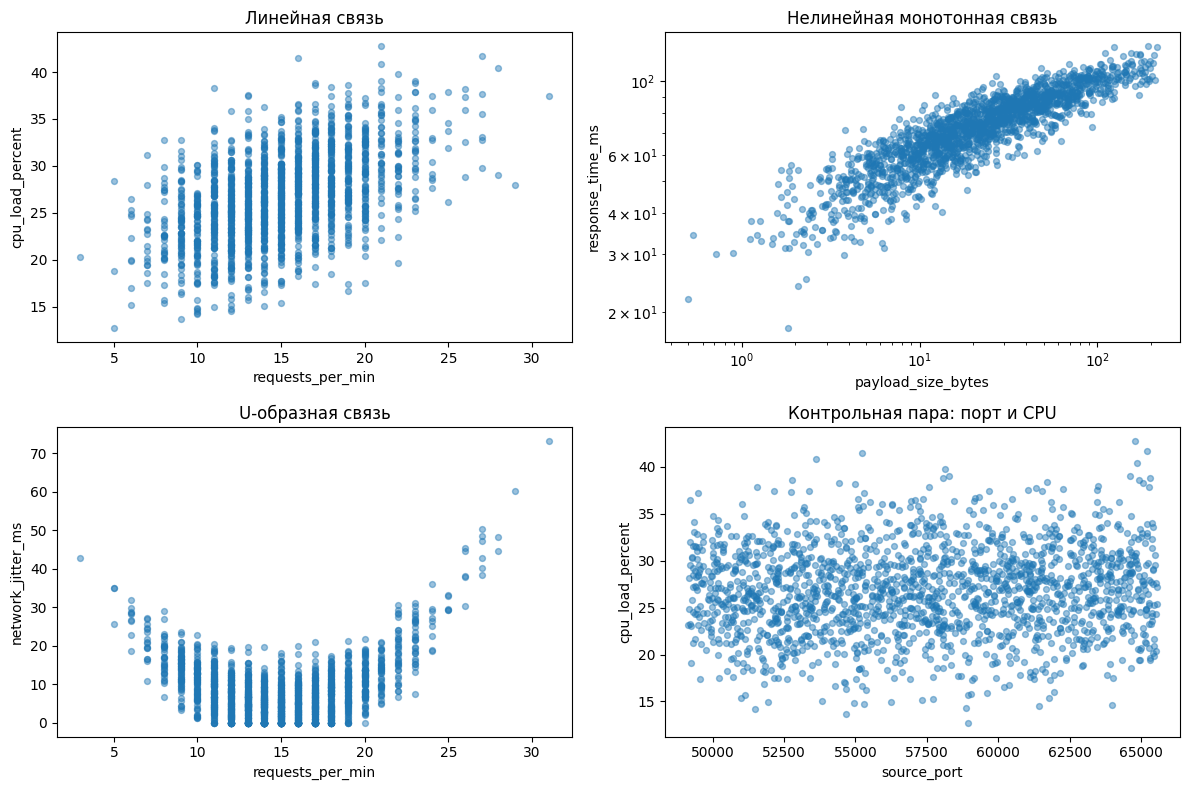

In [7]:
# Каждая точка на графике — одно нормальное событие из очищенной выборки.
pairs = [
    ('requests_per_min', 'cpu_load_percent', 'Линейная связь'),
    ('payload_size_bytes', 'response_time_ms', 'Нелинейная монотонная связь'),
    ('requests_per_min', 'network_jitter_ms', 'U-образная связь'),
    ('source_port', 'cpu_load_percent', 'Контрольная пара: порт и CPU')
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for index in range(len(pairs)):
    x, y, title = pairs[index]
    axes[index].scatter(normal_clean[x], normal_clean[y], s=18, alpha=0.45)
    axes[index].set_xlabel(x)
    axes[index].set_ylabel(y)
    axes[index].set_title(title)

# Для тяжёлых правых хвостов логарифмический масштаб делает график читаемее.
axes[1].set_xscale('log')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

### 2.2. Пирсон, Спирмен и Кендалл

Пирсон характеризует линейную, Спирмен и Кендалл — монотонную связь. `p-value` проверяет нулевую гипотезу соответствующего коэффициента. Порог 0,05 используем как учебное правило, а силу оцениваем по коэффициенту и графику. Для U-образной формы один знак направления не подходит.


In [8]:
# Для каждой пары считаем три коэффициента и их p-value.
correlation_rows = []

for x, y, expected_shape in pairs:
    pearson = stats.pearsonr(normal_clean[x], normal_clean[y])
    spearman = stats.spearmanr(normal_clean[x], normal_clean[y])
    kendall = stats.kendalltau(normal_clean[x], normal_clean[y])

    correlation_rows.append({
        'Пара': x + ' – ' + y,
        'Ожидаемая форма': expected_shape,
        'Пирсон': pearson.statistic,
        'p Пирсона': pearson.pvalue,
        'Спирмен': spearman.statistic,
        'p Спирмена': spearman.pvalue,
        'Кендалл': kendall.statistic,
        'p Кендалла': kendall.pvalue
    })

correlation_results = pd.DataFrame(correlation_rows)
correlation_results.round(4)

,Пара,Ожидаемая форма,Пирсон,p Пирсона,Спирмен,p Спирмена,Кендалл,p Кендалла
0,requests_per_min – cpu_load_percent,Линейная связь,0.5050,0.0000,0.4912,0.0000,0.3522,0.0000
1,payload_size_bytes – response_time_ms,Нелинейная монотонная связь,0.7736,0.0000,0.8927,0.0000,0.7151,0.0000
2,requests_per_min – network_jitter_ms,U-образная связь,0.1578,0.0000,0.0145,0.5404,0.0086,0.6027
3,source_port – cpu_load_percent,Контрольная пара: порт и CPU,0.0630,0.0078,0.0578,0.0147,0.0384,0.0151


### 2.3. Корреляционная матрица Пирсона

In [9]:
# Матрица показывает линейные корреляции между выбранными числовыми столбцами.
matrix_columns = [
    'requests_per_min', 'payload_size_bytes', 'response_time_ms',
    'cpu_load_percent', 'network_jitter_ms', 'source_port', 'packet_rate'
]

pearson_matrix = normal_clean[matrix_columns].corr(method='pearson')
pearson_matrix.round(3)

,requests_per_min,payload_size_bytes,response_time_ms,cpu_load_percent,network_jitter_ms,source_port,packet_rate
requests_per_min,1.000,-0.032,0.013,0.505,0.158,0.012,0.897
payload_size_bytes,-0.032,1.000,0.774,-0.033,-0.052,-0.006,-0.033
response_time_ms,0.013,0.774,1.000,-0.008,-0.040,0.024,0.013
cpu_load_percent,0.505,-0.033,-0.008,1.000,0.098,0.063,0.449
network_jitter_ms,0.158,-0.052,-0.040,0.098,1.000,0.015,0.146
source_port,0.012,-0.006,0.024,0.063,0.015,1.000,0.002
packet_rate,0.897,-0.033,0.013,0.449,0.146,0.002,1.000


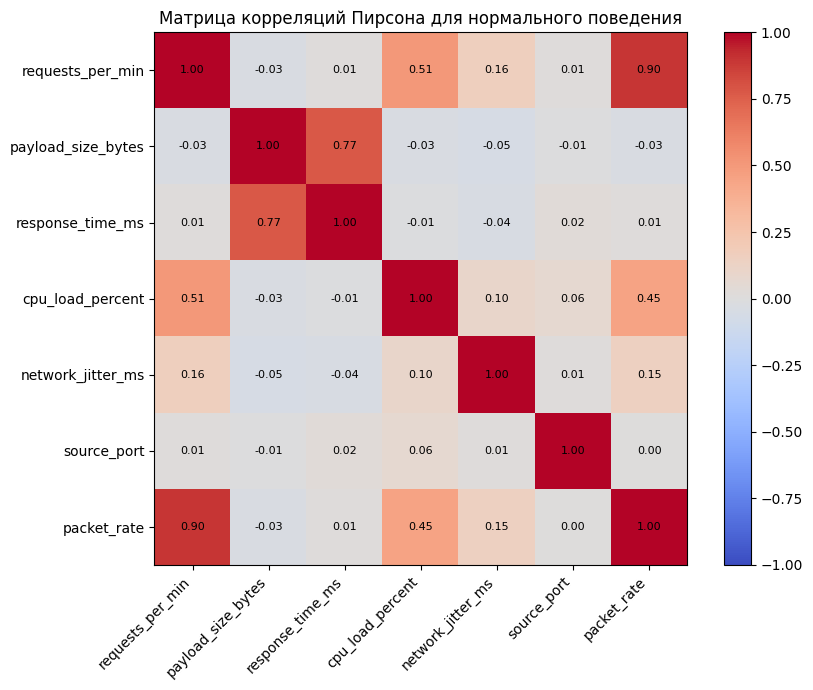

In [10]:
# Цвет и число в каждой клетке показывают коэффициент Пирсона.
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(pearson_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(matrix_columns)))
ax.set_yticks(range(len(matrix_columns)))
ax.set_xticklabels(matrix_columns, rotation=45, ha='right')
ax.set_yticklabels(matrix_columns)

for row in range(len(matrix_columns)):
    for column in range(len(matrix_columns)):
        value = pearson_matrix.iloc[row, column]
        ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=8)

ax.set_title('Матрица корреляций Пирсона для нормального поведения')
plt.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

### 2.4. Чувствительность к крайним значениям

Сравниваем все 1800 нормальных событий с выборкой без верхнего 1% по `payload_size_bytes`. Порог задан по одному признаку заранее и указан в начале блокнота. Разница коэффициентов показывает чувствительность метода к крайним наблюдениям, но сама фильтрация не доказывает, что эти наблюдения ошибочны.


In [11]:
# Сравниваем коэффициенты до и после удаления верхнего 1% размеров нагрузки.
comparison_rows = []

for name, data_part in [('До фильтрации', normal), ('После фильтрации', normal_clean)]:
    x = data_part['payload_size_bytes']
    y = data_part['response_time_ms']
    comparison_rows.append({
        'Данные': name,
        'Число строк': len(data_part),
        'Пирсон': stats.pearsonr(x, y).statistic,
        'Спирмен': stats.spearmanr(x, y).statistic,
        'Кендалл': stats.kendalltau(x, y).statistic
    })

outlier_comparison = pd.DataFrame(comparison_rows)
outlier_comparison.round(4)

,Данные,Число строк,Пирсон,Спирмен,Кендалл
0,До фильтрации,1800,0.6795,0.8959,0.7205
1,После фильтрации,1782,0.7736,0.8927,0.7151


### Вывод по заданию 2

На нормальных событиях частота запросов и загрузка CPU связаны положительно: коэффициент Спирмена ρ = 0,491, связь умеренная и статистически значимая (p < 0,001). Размер полезной нагрузки и время ответа образуют положительную нелинейную монотонную связь: ρ = 0,893 (p < 0,001). Для частоты запросов и джиттера график показывает U-образную форму; Спирмен близок к нулю (ρ = 0,015; p = 0,540), поскольку эта форма не монотонна. Пара «порт источника — загрузка CPU» имеет очень слабую корреляцию (ρ = 0,058), хотя при большом числе наблюдений p = 0,015; порт является идентификатором, поэтому такой результат не следует считать полезной количественной зависимостью.

После удаления 18 наблюдений с наибольшим размером нагрузки коэффициент Пирсона для пары «размер нагрузки — время ответа» изменился с 0,680 до 0,774, а Спирмена — с 0,896 до 0,893. В этой выборке Пирсон заметно чувствительнее к крайним значениям. Отбор верхнего 1% служит только проверкой чувствительности и не означает, что исключённые события ошибочны.

## Задание 3. Нелинейная, частная и множественная связь

### 3.1. Корреляционное отношение η для U-образной зависимости

In [12]:
# Сравниваем обычные корреляции с мерой, способной показать нелинейную связь.
# Разбиваем частоту запросов на 10 равных по ширине интервалов.
request_bins = pd.cut(
    normal_clean['requests_per_min'],
    bins=10,
    include_lowest=True
)

eta = correlation_ratio(request_bins, normal_clean['network_jitter_ms'])
pearson_u = stats.pearsonr(
    normal_clean['requests_per_min'],
    normal_clean['network_jitter_ms']
).statistic
spearman_u = stats.spearmanr(
    normal_clean['requests_per_min'],
    normal_clean['network_jitter_ms']
).statistic

pd.DataFrame({
    'Показатель': ['Пирсон', 'Спирмен', 'Корреляционное отношение η'],
    'Значение': [pearson_u, spearman_u, eta]
}).round(4)

,Показатель,Значение
0,Пирсон,0.1578
1,Спирмен,0.0145
2,Корреляционное отношение η,0.7632


### Вывод по нелинейной связи

Для пары `requests_per_min` и `network_jitter_ms` корреляционное отношение η = 0,763, следовательно η² = 0,582. После разбиения частоты запросов на десять интервалов их групповые средние связаны с заметной долей разброса джиттера. Пирсон (r = 0,158) и Спирмен (ρ = 0,015) не описывают U-образную форму; η не показывает её направление и зависит от выбранных границ интервалов.

### 3.2. Парная и частная корреляция

In [13]:
# Частная корреляция учитывает частоту запросов как третий признак.
pair_corr = normal_clean['cpu_load_percent'].corr(normal_clean['packet_rate'])
controlled_corr = partial_corr(
    normal_clean,
    'cpu_load_percent',
    'packet_rate',
    'requests_per_min'
)

partial_table = pd.DataFrame({
    'Показатель': [
        'Парная корреляция cpu_load_percent – packet_rate',
        'Частная корреляция при фиксированном requests_per_min'
    ],
    'Значение': [pair_corr, controlled_corr]
})
partial_table.round(4)

,Показатель,Значение
0,Парная корреляция cpu_load_percent – packet_rate,0.4495
1,Частная корреляция при фиксированном requests_...,-0.0090


### Вывод по частной корреляции

Парная корреляция загрузки CPU и частоты пакетов положительная (r = 0,449). При учёте `requests_per_min` частная корреляция близка к нулю (r = −0,009). Это согласуется с тем, что оба показателя связаны с частотой запросов. Расчёт показывает ассоциации и не доказывает причинное влияние третьего признака.

### 3.3. Коэффициент множественной корреляции

Строим обычную линейную регрессию средствами NumPy и вычисляем `R = √R²`.

In [14]:
# Сначала строим прогноз загрузки CPU, затем сравниваем его с фактическими значениями.
y = normal_clean['cpu_load_percent'].to_numpy()
x1 = normal_clean['requests_per_min'].to_numpy()
x2 = normal_clean['payload_size_bytes'].to_numpy()

# Первый столбец из единиц нужен для свободного члена регрессии.
X = np.column_stack([np.ones(len(normal_clean)), x1, x2])
coefficients = np.linalg.lstsq(X, y, rcond=None)[0]
predicted = X @ coefficients

ss_residual = ((y - predicted) ** 2).sum()
ss_total = ((y - y.mean()) ** 2).sum()
r_squared = 1 - ss_residual / ss_total
multiple_r = np.sqrt(max(0, r_squared))

print('Коэффициенты модели:', coefficients.round(4))
print(f'R² = {r_squared:.4f}')
print(f'R = {multiple_r:.4f} ({strength(multiple_r)} множественная связь)')

Коэффициенты модели: [ 1.7798e+01  6.0390e-01 -2.2000e-03]
R² = 0.2554
R = 0.5053 (умеренная множественная связь)


### Вывод по множественной корреляции

Линейная модель для загрузки CPU с признаками `requests_per_min` и `payload_size_bytes` дала R² = 0,255 и R = 0,505. По принятой в блокноте шкале это умеренная множественная связь. R не имеет знака и сам по себе не показывает направление действия отдельных признаков; коэффициенты модели и графики нужно рассматривать отдельно.

## Задание 4. Связь категориальных признаков

### 4.1. `attack_type` и `severity_level`

In [15]:
# Считаем, сколько событий каждого уровня серьёзности приходится на каждый тип.
contingency = pd.crosstab(df['attack_type'], df['severity_level'])
contingency

severity_level,Critical,High,Low,Medium
attack_type,,,,
BruteForce,36,134,16,114
DDoS,139,153,5,53
Malware,69,99,4,28
Normal,7,84,1310,399
Phishing,25,117,27,131
SQLi,117,111,0,22


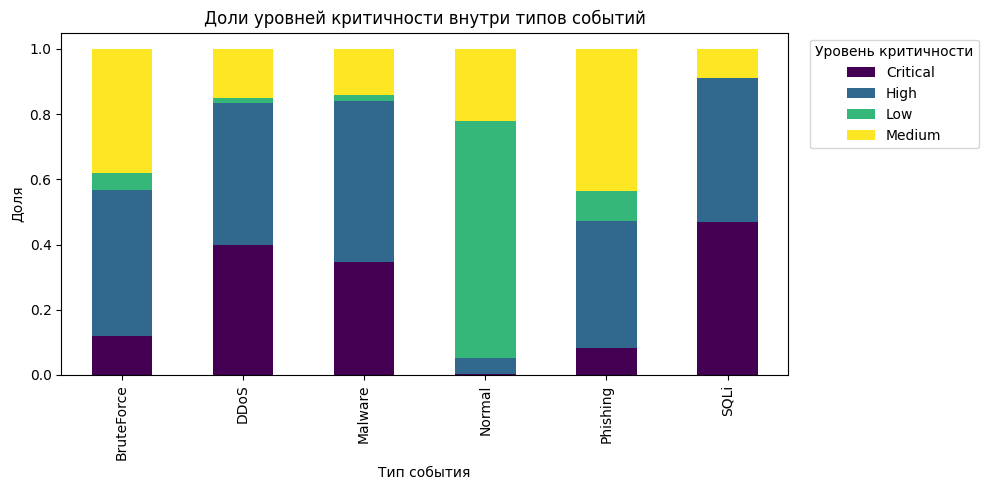

In [16]:
# Превращаем количества в доли, чтобы сравнивать группы разного размера.
normalized = contingency.div(contingency.sum(axis=1), axis=0)
normalized.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='viridis')
plt.title('Доли уровней критичности внутри типов событий')
plt.xlabel('Тип события')
plt.ylabel('Доля')
plt.legend(title='Уровень критичности', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [17]:
# Критерий проверяет независимость, а V Крамера оценивает силу связи.
chi_result = stats.chi2_contingency(contingency, correction=False)
v_value = cramers_v(contingency)
expected = pd.DataFrame(
    chi_result.expected_freq,
    index=contingency.index,
    columns=contingency.columns
)

print(f'χ² = {chi_result.statistic:.3f}')
print('p-value < 1e-300' if chi_result.pvalue == 0 else f'p-value = {chi_result.pvalue:.6g}')
print(f'Степени свободы = {chi_result.dof}')
print(f'Минимальная ожидаемая частота = {expected.to_numpy().min():.2f}')
print(f'Ячеек с ожидаемой частотой меньше 5: {(expected < 5).sum().sum()}')
print(f'V Крамера = {v_value:.3f} — {strength(v_value)} связь')

χ² = 2317.343
p-value < 1e-300
Степени свободы = 15
Минимальная ожидаемая частота = 24.56
Ячеек с ожидаемой частотой меньше 5: 0
V Крамера = 0.491 — умеренная связь


### Вывод по категориальным признакам

Критерий χ² для `attack_type` и `severity_level` даёт χ² = 2317,343 при 15 степенях свободы и p < 1 × 10⁻³⁰⁰. Минимальная ожидаемая частота равна 24,56, поэтому в таблице нет ячеек с ожидаемой частотой менее 5. Независимость признаков отвергается. V Крамера = 0,491 показывает умеренную силу связи: очень малое p само по себе не означает столь же сильный эффект. Для SOC тип события может быть полезен при оценке серьёзности, но не заменяет проверку конкретного инцидента.

### 4.2. Дополнительно: таблица 2×2, φ и коэффициент Юла Q

In [18]:
# Для двух бинарных признаков строим таблицу из четырёх ячеек.
# Явно задаём порядок 0 и 1, чтобы знак коэффициента был понятен.
table_2x2 = pd.crosstab(df['is_after_hours'], df['incident_confirmed'])
table_2x2 = table_2x2.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
result_2x2 = stats.chi2_contingency(table_2x2, correction=False)

a = table_2x2.loc[0, 0]
b = table_2x2.loc[0, 1]
c = table_2x2.loc[1, 0]
d = table_2x2.loc[1, 1]

# Для таблицы 2×2 φ может быть как положительным, так и отрицательным.
phi_denominator = np.sqrt((a + b) * (c + d) * (a + c) * (b + d))
phi = (a * d - b * c) / phi_denominator if phi_denominator else np.nan
q_denominator = a * d + b * c
yule_q = (a * d - b * c) / q_denominator if q_denominator else np.nan

display(table_2x2)
print(f'φ = {phi:.3f}')
print(f'Q Юла = {yule_q:.3f}')
print(f'p-value χ² = {result_2x2.pvalue:.4g}')


incident_confirmed,0,1
is_after_hours,,
0,1364,556
1,568,712


φ = 0.267
Q Юла = 0.509
p-value χ² = 1.412e-51


### Вывод по таблице 2 × 2

Для признаков `is_after_hours` и `incident_confirmed` получены φ = 0,267 и Q Юла = 0,509; критерий χ² даёт p < 0,001. В этой выборке подтверждённые события относительно чаще встречаются во внерабочее время. φ показывает слабую положительную связь, но не доказывает, что время суток влияет на подтверждение события.

## Задание 5. Количественный и категориальный признаки

### 5.1. `incident_confirmed` и `detection_time_sec`

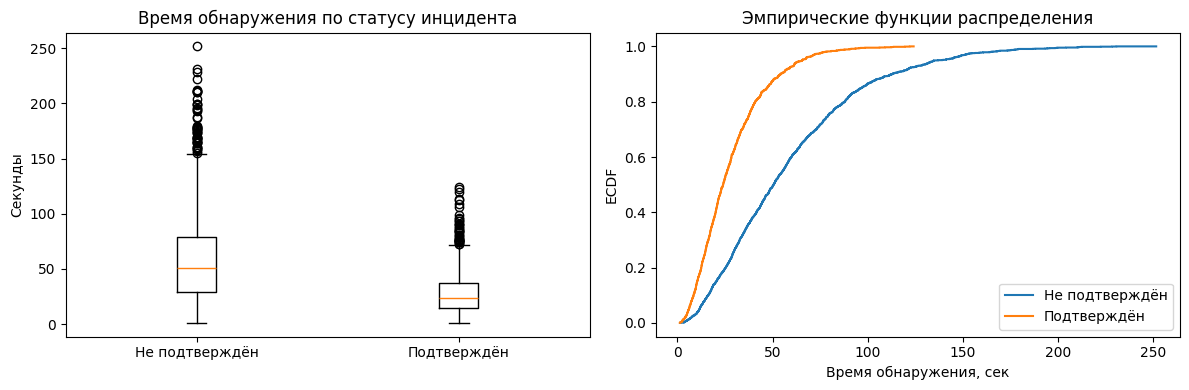

In [19]:
# Разделяем время обнаружения по статусу и строим два вида графиков.
confirmed_time = df.loc[df['incident_confirmed'] == True, 'detection_time_sec'].dropna()
not_confirmed_time = df.loc[df['incident_confirmed'] == False, 'detection_time_sec'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(
    [not_confirmed_time, confirmed_time],
    tick_labels=['Не подтверждён', 'Подтверждён']
)
axes[0].set_title('Время обнаружения по статусу инцидента')
axes[0].set_ylabel('Секунды')

for values, label in [
    (not_confirmed_time, 'Не подтверждён'),
    (confirmed_time, 'Подтверждён')
]:
    sorted_values = np.sort(values)
    ecdf = np.arange(1, len(sorted_values) + 1) / len(sorted_values)
    axes[1].step(sorted_values, ecdf, label=label)

axes[1].set_title('Эмпирические функции распределения')
axes[1].set_xlabel('Время обнаружения, сек')
axes[1].set_ylabel('ECDF')
axes[1].legend()
plt.tight_layout()
plt.show()

In [20]:
# Сравниваем распределения и считаем связь времени с бинарным статусом.
mw_result = stats.mannwhitneyu(
    confirmed_time,
    not_confirmed_time,
    alternative='two-sided'
)
pb_result = stats.pointbiserialr(
    df['incident_confirmed'].astype(int),
    df['detection_time_sec']
)

print(f'Медиана подтверждённых: {confirmed_time.median():.2f} сек')
print(f'Медиана неподтверждённых: {not_confirmed_time.median():.2f} сек')
print(f'U Манна–Уитни = {mw_result.statistic:.1f}, p = {mw_result.pvalue:.6g}')
print(f'Точечно-бисериальная корреляция = {pb_result.statistic:.3f}, p = {pb_result.pvalue:.6g}')

Медиана подтверждённых: 24.09 сек
Медиана неподтверждённых: 50.59 сек
U Манна–Уитни = 588070.0, p = 5.58673e-137
Точечно-бисериальная корреляция = -0.412, p = 4.06959e-131


### Вывод по времени обнаружения

Медианное время обнаружения подтверждённых событий равно 24,09 секунды, неподтверждённых — 50,59 секунды. Критерий Манна–Уитни показывает различие распределений (p < 0,001), а точечно-бисериальная корреляция отрицательна (r = −0,412; p < 0,001): значение 1 у признака подтверждения связано с меньшим временем. Критерий Манна–Уитни не является самостоятельной проверкой равенства медиан, а наблюдаемая связь не устанавливает причину различия.

### 5.2. `attack_type` и `data_exfil_mb`

Категорию `Normal` исключаем, потому что вопрос относится именно к типам атак.

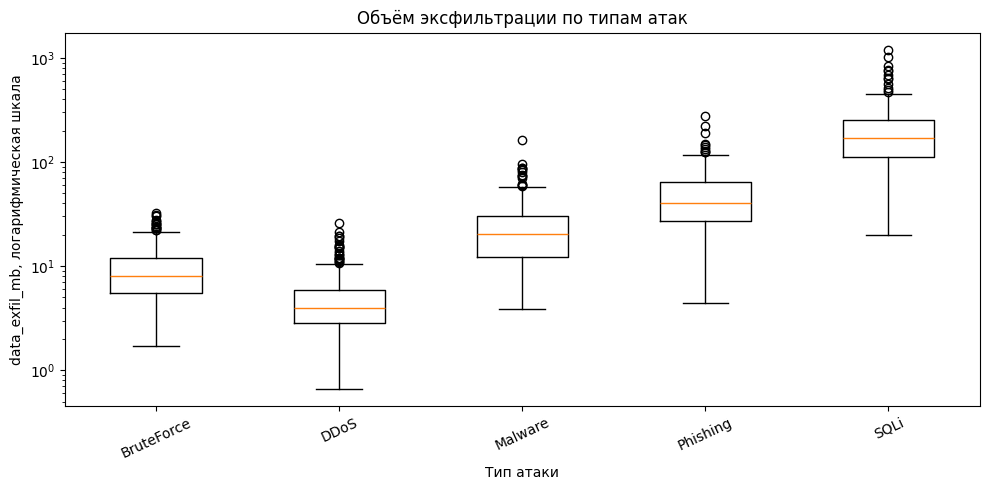

In [21]:
# Берём только атаки, чтобы сравнивать объём эксфильтрации между их типами.
attacks = df[df['attack_type'] != 'Normal'].copy()
attack_names = sorted(attacks['attack_type'].unique())
exfil_groups = []

for name in attack_names:
    values = attacks.loc[attacks['attack_type'] == name, 'data_exfil_mb'].dropna()
    exfil_groups.append(values)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(exfil_groups, tick_labels=attack_names)
ax.set_yscale('log')
ax.set_title('Объём эксфильтрации по типам атак')
ax.set_xlabel('Тип атаки')
ax.set_ylabel('data_exfil_mb, логарифмическая шкала')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [22]:
# Сначала проверяем все группы, затем отдельные пары с поправкой Холма.
kruskal_result = stats.kruskal(*exfil_groups)

pair_names = []
raw_p_values = []
u_values = []

for first, second in combinations(range(len(attack_names)), 2):
    result = stats.mannwhitneyu(exfil_groups[first], exfil_groups[second],
                                alternative='two-sided')
    pair_names.append(attack_names[first] + ' – ' + attack_names[second])
    u_values.append(result.statistic)
    raw_p_values.append(result.pvalue)

# Поправка Холма: упорядочиваем p и умножаем их на 10, 9, ..., 1.
# Каждое следующее исправленное p не должно быть меньше предыдущего.
number_of_tests = len(raw_p_values)
order = np.argsort(raw_p_values)
adjusted_p_values = np.zeros(number_of_tests)
previous_adjusted = 0

for rank in range(number_of_tests):
    original_index = order[rank]
    adjusted = raw_p_values[original_index] * (number_of_tests - rank)
    adjusted = min(1.0, max(adjusted, previous_adjusted))
    adjusted_p_values[original_index] = adjusted
    previous_adjusted = adjusted

posthoc = pd.DataFrame({
    'Пара': pair_names,
    'U': u_values,
    'p без поправки': raw_p_values,
    'p Холма': adjusted_p_values,
    'Значимо при α=0.05': adjusted_p_values < 0.05
})

# η² — доля разброса исходного объёма, связанная с группами attack_type.
# Статистика H Краскела–Уоллиса не используется в этой формуле.
eta_squared = correlation_ratio(attacks['attack_type'], attacks['data_exfil_mb']) ** 2

print(f'H Краскела–Уоллиса = {kruskal_result.statistic:.3f}')
print(f'p-value = {kruskal_result.pvalue:.6g}')
print(f'η² для исходного data_exfil_mb = {eta_squared:.3f}')
print('η² чувствительно к сильной асимметрии и крайним значениям.')
display(posthoc)


H Краскела–Уоллиса = 1134.235
p-value = 2.87344e-244
η² для исходного data_exfil_mb = 0.550
η² чувствительно к сильной асимметрии и крайним значениям.


,Пара,U,p без поправки,p Холма,Значимо при α=0.05
0,BruteForce – DDoS,83057.0,1.578435e-37,4.735304e-37,True
1,BruteForce – Malware,9825.0,3.250237e-37,6.500475e-37,True
2,BruteForce – Phishing,2844.5,9.872362e-88,6.910653e-87,True
3,BruteForce – SQLi,19.0,1.037470e-90,8.299761e-90,True
4,DDoS – Malware,3255.5,3.748389e-70,1.499356e-69,True
5,DDoS – Phishing,719.5,2.266836e-104,2.266836e-103,True
6,DDoS – SQLi,2.0,5.592999e-97,5.033699e-96,True
7,Malware – Phishing,13229.5,3.120164e-26,3.120164e-26,True
8,Malware – SQLi,550.0,3.741012e-71,1.870506e-70,True
9,Phishing – SQLi,3492.0,5.167857e-75,3.100714e-74,True


### Вывод по объёму эксфильтрации

Распределения `data_exfil_mb` между типами атак различаются: H Краскела–Уоллиса = 1134,235; p < 0,001. После поправки Холма значимы все 10 попарных сравнений. Для исходного объёма η² = 0,550: тип атаки связан примерно с 55% его суммарного разброса в этой выборке. Этот показатель чувствителен к большим значениям и описывает долю дисперсии; он не вычисляется из статистики H. Для рабочих порогов SOC нужны проверка на независимых данных и оценка ошибок.

### 5.3. Итоговая записка для SOC

### Итоговый вывод для SOC

В штатном трафике частота запросов и загрузка CPU имеют умеренную положительную связь (ρ = 0,491; p < 0,001), поэтому отклонения от этого профиля могут стать поводом для проверки. Между частотой запросов и джиттером видна U-образная зависимость (η = 0,763), которую почти не отражает коэффициент Спирмена. Тип события связан с уровнем серьёзности статистически значимо (V Крамера = 0,491), но эта связь не определяет серьёзность каждого отдельного случая. Распределения времени обнаружения для подтверждённых и неподтверждённых событий различаются (медианы 24,09 и 50,59 секунды; p Манна–Уитни < 0,001), при этом тест не проверяет только равенство медиан. Объём эксфильтрации различается для всех 10 пар типов атак после поправки Холма, что может помочь при разработке разных порогов, если дополнительно оценить ложные срабатывания. Все выводы относятся к этой выборке и не доказывают причинную связь между признаками.